# Out-of-time cohorts: SME PD by vintage through 2008 (C03)

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 01 to 03 of this topic
- **Reading time:** about 55 minutes

## Objectives

By the end of this notebook you can:

- explain why a panel of loans is validated by vintage, out of time, and why the target of a vintage may be read only at its 5-year mark;
- read the five rolling training windows of C03 and check, on dates, that each one closes before its test cohort is approved;
- read the observed and predicted 5-year PD of fifteen approval years, the cumulative curves by month and the calibration by decile;
- recompute the portfolio rows of the battery of each cohort with the engine, and explain why the one-sided level tests stay green while the scorecard over-predicts the risk.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import stats

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))


riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

Case C03 is the PD of small-business loans by vintage. The data is the U.S. Small Business Administration 7(a) FOIA loan file (owner: U.S. SBA; licence "U.S. Government Works", class `mirror-allowed`; https://data.sba.gov/dataset/7a-504-foia; loans approved from fiscal year 1991, as of 2026-06-30). It is a federal guarantee programme for small-business loans, not the SME book of a bank: the file has no delinquency history, no balance and no rating (finding `F-DATA`). The pipeline fitted six models on approval fiscal years up to a cut-off and scored five later cohorts. This notebook reads what it committed:

- `data/derived/C03/fy2006-07.json`, `fy2008-10.json`, `fy2011-14.json`, `fy2015-17.json` and `fy2018-20.json`: one file per test cohort, with the vintage summaries and curves, the calibration by decile, the stability, the comparison of the models and the battery of tests.
- `data/derived/C03/models-sba-7a.json`: the target definition, the five training windows and the ladder.

The raw file stays outside the repository; a re-fit needs the documented fetch, and nothing here does. The next cell loads the six files.

In [2]:
# Load the five cohort files and the models file of C03
ROOT = Path("../../..").resolve()
derived = ROOT / "data" / "derived" / "C03"
names = ["fy2006-07", "fy2008-10", "fy2011-14", "fy2015-17", "fy2018-20"]
cohorts = {n: json.loads((derived / f"{n}.json").read_text(encoding="utf-8")) for n in names}
fit = json.loads((derived / "models-sba-7a.json").read_text(encoding="utf-8"))["fit"]

LANG = "en"
# The engine's light values, named in this language
LIGHT = {"green": "green", "amber": "amber", "red": "red", "not_evaluated": "none"}
print("test cohorts:", [cohorts[n]["outputs"]["cohort"]["label"][LANG] for n in names])
print("models in the ladder:", [r["rung_id"] for r in fit["ladder"]])
print("baked by riskvalidation", {cohorts[n]["provenance"]["riskvalidation_version"] for n in names}, "| installed", rv.__version__)


test cohorts: ['FY2006-07', 'FY2008-10', 'FY2011-14', 'FY2015-17', 'FY2018-20']
models in the ladder: ['P0-constant', 'P1-scorecard', 'P2a-l1', 'P2b-pltr', 'P3-ebm', 'P4-lightgbm']
baked by riskvalidation {'1.0.1'} | installed 1.0.1


## Method

### Step 1: why a vintage, and what "out of time" means

A loan portfolio changes over time: the economy, the lenders' policies and the mix of borrowers move. A model validated on a random slice of the same years is validated on loans it could have learned from: a validation by random split of a panel lets the future leak into the training. The out-of-time design (the C03 split in `docs/design/SDD.md`, and the leakage rules of the research basis) answers with two rules:

1. **vintages are groups of loans approved in the same fiscal year** (1 October to 30 September), and the model is trained on early vintages and tested on later ones;
2. **the target of a vintage is read only at its 5-year mark**: a loan is an event when it charged off within 60 months of approval, and a vintage enters the training only when the 60th month of its last loan has passed, so that its target is known.

A loan approved on the last day of a fiscal year reaches its 5-year mark on 30 September five years later; that date is the **cut-off** of a training window. The next cell prints the five windows from the committed models file and checks two things on the dates: the cut-off is the 5-year mark of the last training year, and it falls before the first approval of the test cohort.

In [3]:
# Print the five training windows and check their cut-off dates against the test cohort
print(f"{'test cohort':14s} {'trained on':>14s} {'cut-off':>11s} {'first approval of the test':>34s} {'loans':>8s} {'charge-offs':>11s} {'crisis in training':>22s}")
for w in fit["cohort_windows"]:
    train = w["training"]
    cutoff = date.fromisoformat(train["cutoff_date"])
    first_approval = date(w["first_fy"] - 1, 10, 1)
    assert cutoff == date(train["last_fy"] + 5, 9, 30) and cutoff < first_approval
    print(f"{w['label'][LANG]:14s} {'FY' + str(train['first_fy']) + '-' + str(train['last_fy']):>14s} {train['cutoff_date']:>11s} {first_approval.isoformat():>34s} {train['n_loans']:8d} {train['n_events']:11d} {str(train['crisis_included']):>22s}")
print("every cut-off is the 5-year mark of its last training year and precedes the test cohort")


test cohort        trained on     cut-off         first approval of the test    loans charge-offs     crisis in training
FY2006-07         FY1991-2000  2005-09-30                         2005-10-01   330682       23320                  False
FY2008-10         FY1991-2002  2007-09-30                         2007-10-01   413083       28393                  False
FY2011-14         FY1991-2005  2010-09-30                         2010-10-01   627594       50614                   True
FY2015-17         FY1991-2009  2014-09-30                         2014-10-01   900254      110349                   True
FY2018-20         FY1991-2012  2017-09-30                         2017-10-01  1024597      115237                   True
every cut-off is the 5-year mark of its last training year and precedes the test cohort


### Step 2: the target and the right-censoring rule

The committed target definition is explicit about a trap of loan data: a loan that has not been observed for 60 months and has not charged off has **no outcome yet** (it is right-censored). Calling it a non-event would bias the PD of a young vintage down. The rule of C03 is to read each vintage only at its 5-year mark, where every loan has been observed for 60 months, so that a loan still active at month 60 is a true non-event, and a loan observed for less than 60 months is counted apart, never as performing. The next cell prints the definition from the committed file and, for the fifteen vintages, the loans, the loans excluded as censored, and whether the 5-year mark was observed.

In [4]:
# Print the target definition and the loans, the censored loans and the 5-year mark of each vintage
print(fit["target"]["definition"][LANG])
print()
vintages = []
for n in names:
    vintages.extend(cohorts[n]["outputs"]["vintage_summary"]["rows"])
print(f"{'FY':>5s} {'loans':>8s} {'resolved':>9s} {'censored':>10s} {'5-year mark':>16s} {'observed':>10s}")
for v in vintages:
    print(f"{v['fiscal_year']:5d} {v['n']:8d} {v['n_resolved']:9d} {v['n_exempt_censored']:10d} {v['five_year_mark_date']:>16s} {str(v['mark_observed']):>10s}")
print("vintages:", len(vintages), "| censored loans in total:", sum(v["n_exempt_censored"] for v in vintages))


A loan is an event when the file shows it charged off within 60 months of approval, on or before the observation date. The target of a vintage is read only at its 5-year mark (30 September of the fiscal year plus 5). A loan observed for the whole 60 months without a charge-off, paid in full, charged off later or still active, is a non-event: the file shows a charge-off as CHGOFF, never as an active loan. A loan observed for less than 60 months and not charged off (EXEMPT, active) is right-censored: it has no outcome, is counted apart and is never counted as performing.

   FY    loans  resolved   censored      5-year mark   observed
 2006    86393     86393          0       2011-09-30       True
 2007    88134     88134          0       2012-09-30       True
 2008    61539     61539          0       2013-09-30       True
 2009    36594     36594          0       2014-09-30       True
 2010    39890     39890          0       2015-09-30       True
 2011    45592     45592          0    

### Step 3: observed against predicted, vintage by vintage

For a vintage, the observed 5-year PD is the share of its loans that charged off within 60 months, and the predicted 5-year PD is the mean PD the scorecard (rung P1) gave its loans. Their difference is the calibration gap: positive when the model under-estimates the risk, negative when it over-estimates it. The AUC of the vintage says whether the ranking held. The next cell prints the fifteen vintages and the figure draws the gap: the loans approved in 2006 to 2008 defaulted at 21% to 28% against 7% to 9% predicted, the model having been trained before the crisis (for the first cohorts), and the later vintages are over-predicted.

In [5]:
# Print observed and predicted 5-year PD, the gap, the Brier score and the AUC of each vintage
print(f"{'FY':>5s} {'loans':>8s} {'observed':>10s} {'predicted':>10s} {'gap':>8s} {'Brier':>7s} {'AUC':>7s}")
for v in vintages:
    print(f"{v['fiscal_year']:5d} {v['n']:8d} {v['observed_5y_pd']:10.4f} {v['predicted_5y_pd']:10.4f} {v['gap']:8.4f} {v['brier']:7.4f} {v['auc']:7.4f}")
gap_is_obs_minus_pred = all(abs(v["gap"] - (v["observed_5y_pd"] - v["predicted_5y_pd"])) < 1e-6 for v in vintages)
print("gap = observed minus predicted:", gap_is_obs_minus_pred)


   FY    loans   observed  predicted      gap   Brier     AUC
 2006    86393     0.2231     0.0880   0.1351  0.1649  0.8332
 2007    88134     0.2758     0.0876   0.1882  0.2079  0.8204
 2008    61539     0.2127     0.0735   0.1391  0.1675  0.8132
 2009    36594     0.0838     0.0615   0.0223  0.0719  0.7845
 2010    39890     0.0490     0.0541  -0.0051  0.0437  0.8102
 2011    45592     0.0365     0.0649  -0.0284  0.0346  0.7983
 2012    38861     0.0327     0.0655  -0.0327  0.0312  0.8261
 2013    40400     0.0307     0.0620  -0.0313  0.0295  0.8236
 2014    45942     0.0352     0.0636  -0.0284  0.0326  0.8235
 2015    55387     0.0385     0.0882  -0.0497  0.0392  0.8085
 2016    56759     0.0387     0.0836  -0.0449  0.0392  0.7932
 2017    56057     0.0431     0.0804  -0.0373  0.0424  0.7841
 2018    54171     0.0466     0.0668  -0.0201  0.0452  0.8104
 2019    45664     0.0391     0.0576  -0.0185  0.0397  0.8321
 2020    36456     0.0259     0.0555  -0.0296  0.0288  0.8418
gap = ob

The figure draws the gap (red where the scorecard under-estimates the risk, blue where it over-estimates it) and the AUC of each vintage.

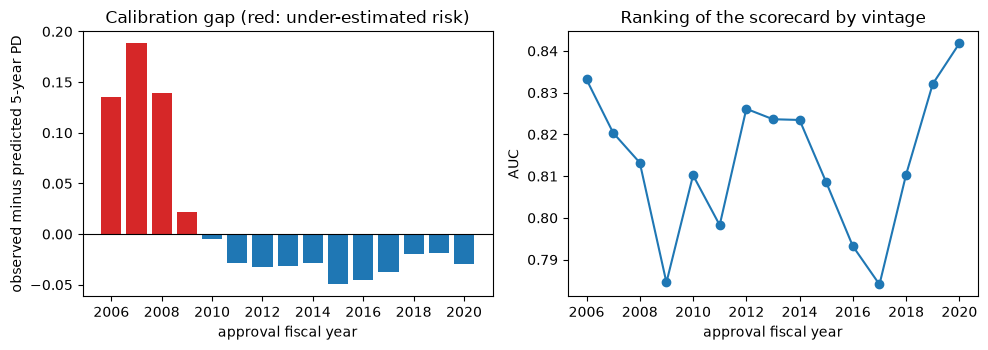

In [6]:
# Draw the calibration gap and the AUC of each vintage
years = [v["fiscal_year"] for v in vintages]
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.6))
left.bar(years, [v["gap"] for v in vintages], color=["tab:red" if v["gap"] > 0 else "tab:blue" for v in vintages])
left.axhline(0, color="black", linewidth=0.8)
left.set_xlabel("approval fiscal year")
left.set_ylabel("observed minus predicted 5-year PD")
left.set_title("Calibration gap (red: under-estimated risk)")
right.plot(years, [v["auc"] for v in vintages], marker="o")
right.set_xlabel("approval fiscal year")
right.set_ylabel("AUC")
right.set_title("Ranking of the scorecard by vintage")
fig.tight_layout()
plt.show()


### Step 4: the cumulative curves by month

A vintage is not one number but a curve: the cumulative share of the vintage charged off at months 12, 24, 36, 48 and 60. The model predicts the whole curve and the file observes it. A curve that is right at month 60 and wrong in its shape would still be misleading for a lifetime estimate. The next cell prints the last point of every vintage of the cohort FY2008-10 (the crisis years) and of FY2015-17, and the figure draws their curves, predicted against observed.

FY2008 month 60: predicted 0.0735 | observed 0.2127
FY2009 month 60: predicted 0.0615 | observed 0.0838
FY2010 month 60: predicted 0.0541 | observed 0.0490
FY2015 month 60: predicted 0.0882 | observed 0.0385
FY2016 month 60: predicted 0.0836 | observed 0.0387
FY2017 month 60: predicted 0.0804 | observed 0.0431


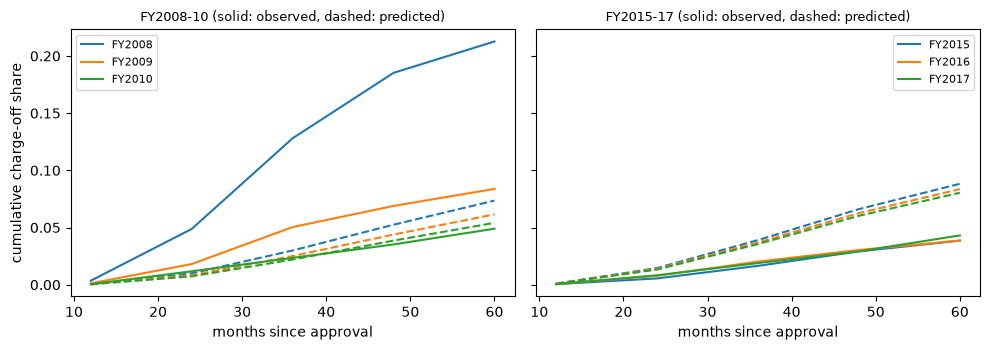

In [7]:
# Print the curves of the crisis cohort and of FY2015-17 and draw them, predicted against observed
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, name in zip(axes, ("fy2008-10", "fy2015-17")):
    for curve in cohorts[name]["outputs"]["vintage_curves"]:
        line, = ax.plot(curve["months"], curve["predicted_cumulative_pd"], linestyle="--")
        ax.plot(curve["months"], curve["observed_cumulative_pd"], color=line.get_color(), label=f"FY{curve['fiscal_year']}")
        print(f"FY{curve['fiscal_year']} month {curve['months'][-1]}: predicted {curve['predicted_cumulative_pd'][-1]:.4f} | observed {curve['observed_cumulative_pd'][-1]:.4f}")
    ax.set_title(cohorts[name]["outputs"]["cohort"]["label"][LANG] + " (solid: observed, dashed: predicted)", fontsize=9)
    ax.set_xlabel("months since approval")
    ax.legend(fontsize=8)
axes[0].set_ylabel("cumulative charge-off share")
fig.tight_layout()
plt.show()


### Step 5: the battery of each cohort, recomputed

Each cohort file commits the battery of the engine on the scorecard (rung P1), with one portfolio row per test and one row per vintage for the level tests. The portfolio of a cohort has $N$ loans, $D$ charge-offs and a mean predicted PD; the vintage summaries above contain all three, so the engine can be called on them and compared with the committed rows. The next cell rebuilds $N$, $D$ and the mean PD of each cohort from its vintages, calls the Jeffreys test and the Vasicek-adjusted binomial test (asset correlation 0.12, the modelling assumption the committed row states in its notes), and compares both p-values with the committed ones. The tests are one-sided: they reject when the defaults exceed what the PD allows.

In [8]:
# Rebuild N, D and the mean PD of each cohort from its vintages, call the engine and compare with the committed rows
from riskvalidation.validation import pd_binomial_vasicek, pd_jeffreys

policy = rv.default_policy()


def portfolio_row(doc, test_id, model_id="P1-scorecard"):
    return next(t for t in doc["tests"] if t["test_id"] == test_id and t["model_id"] == model_id and t["segment"] == "portfolio")


print(f"{'cohort':10s} {'N':>8s} {'D':>6s} {'mean PD':>8s} {'rate':>7s} {'p Jeffreys':>11s} {'committed':>11s} {'p Vasicek':>10s} {'committed':>11s}")
for n in names:
    rows = cohorts[n]["outputs"]["vintage_summary"]["rows"]
    total = sum(v["n"] for v in rows)
    n_events = sum(round(v["observed_5y_pd"] * v["n"]) for v in rows)
    mean_pd = sum(v["predicted_5y_pd"] * v["n"] for v in rows) / total
    jef = pd_jeffreys(n=total, d=n_events, pd=mean_pd, policy=policy, model_id="P1-scorecard", segment="portfolio")
    vas = pd_binomial_vasicek(n=total, d=n_events, pd=mean_pd, rho=0.12, policy=policy, model_id="P1-scorecard", segment="portfolio")
    assert (portfolio_row(cohorts[n], "pd.jeffreys")["n"], portfolio_row(cohorts[n], "pd.jeffreys")["n_events"]) == (total, n_events)
    print(f"{n:10s} {total:8d} {n_events:6d} {mean_pd:8.4f} {n_events / total:7.4f} {jef.p_value:11.4f} {portfolio_row(cohorts[n], 'pd.jeffreys')['p_value']:11.4f} {vas.p_value:10.4f} {portfolio_row(cohorts[n], 'pd.binomial_vasicek')['p_value']:11.4f}")


cohort            N      D  mean PD    rate  p Jeffreys   committed  p Vasicek   committed
fy2006-07    174527  43581   0.0878  0.2497      0.0000      0.0000     0.0154      0.0154
fy2008-10    138023  18108   0.0647  0.1312      0.0000      0.0000     0.0845      0.0845
fy2011-14    170795   5790   0.0640  0.0339      1.0000      1.0000     0.7222      0.7222
fy2015-17    168203   6745   0.0840  0.0401      1.0000      1.0000     0.7841      0.7841
fy2018-20    136291   5256   0.0607  0.0386      1.0000      1.0000     0.6446      0.6446


Now the whole battery of the scorecard, cohort by cohort: the p-value of each test and its light. Read the table as a validator would: not row by row but column by column, asking which cohorts the battery objects to.

In [9]:
# Print the portfolio rows of the scorecard battery for the five cohorts
ids = ["disc.auc_vs_initial", "pd.jeffreys", "pd.binomial", "pd.binomial_vasicek", "pd.hosmer_lemeshow", "pd.spiegelhalter", "stability.psi"]
print(f"{'test':22s}" + "".join(f"{n:>18s}" for n in names))
for test_id in ids:
    line = f"{test_id:22s}"
    for n in names:
        row = portfolio_row(cohorts[n], test_id)
        line += f"{row['p_value']:12.3g} {LIGHT[row['light']]:>5s}"
    print(line)


test                           fy2006-07         fy2008-10         fy2011-14         fy2015-17         fy2018-20
disc.auc_vs_initial              1 green           1 green       0.977 green    1.03e-08   red       0.468 green
pd.jeffreys                      0   red           0   red           1 green           1 green           1 green
pd.binomial                      0   red           0   red           1 green           1 green           1 green
pd.binomial_vasicek         0.0154 amber      0.0845 green       0.722 green       0.784 green       0.645 green
pd.hosmer_lemeshow               0   red           0   red           0   red           0   red           0   red
pd.spiegelhalter                 0   red           0   red           1 green           1 green           1 green
stability.psi                    0   red           0   red           0   red           0   red           0   red


Two readings of this table matter. First, the **one-sided tests reject only an under-estimate**. From FY2011 on the scorecard over-predicts (the gap is negative), so the Jeffreys, binomial and Spiegelhalter tests have p-values near 1 and stay green. That is correct for what they ask: they do not claim that the PD is right, only that the defaults are not above it. A bank that validates only with level tests would miss an over-estimate that ties capital up. Second, the **two-sided fit test, Hosmer-Lemeshow, is red in every cohort**, and so is the PSI. The AUC against development is red for FY2015-17 alone. The next cell recomputes that statistic from the committed extras, as in notebook 03: the development AUC and its variance, the AUC of the cohort and its variance, and the one-sided p-value.

In [10]:
# Recompute the AUC against development of every cohort from the committed extras
print(f"{'cohort':10s} {'AUC at development':>20s} {'AUC now':>9s} {'z recomputed':>14s} {'p recomputed':>14s} {'p committed':>14s}")
for n in names:
    row = portfolio_row(cohorts[n], "disc.auc_vs_initial")
    e = row["extras"]
    z = (e["auc_initial"] - e["auc_current"]) / np.sqrt(e["s2_total"])
    print(f"{n:10s} {e['auc_initial']:20.4f} {e['auc_current']:9.4f} {z:14.3f} {stats.norm.sf(z):14.3g} {row['p_value']:14.3g}")


cohort       AUC at development   AUC now   z recomputed   p recomputed    p committed
fy2006-07                0.7967    0.8252         -4.626              1              1
fy2008-10                0.7832    0.8149         -4.800              1              1
fy2011-14                0.8042    0.8170         -1.998          0.977          0.977
fy2015-17                0.8226    0.7935          5.606       1.03e-08       1.03e-08
fy2018-20                0.8268    0.8264          0.080          0.468          0.468


### Step 6: calibration by decile

The portfolio hides where the model is wrong. The committed calibration groups a cohort's loans into ten deciles of PD and gives, for each, the predicted PD, the observed rate and a 95% interval of the observed rate. The next cell counts in how many deciles the predicted PD falls outside the interval of what was observed, for each cohort, and the figure draws the deciles of FY2015-17 on a logarithmic axis, where the predicted PD of the lowest deciles is several times what was observed.

fy2006-07  deciles: 10 | predicted above the interval: 0 | predicted below it: 10
fy2008-10  deciles: 10 | predicted above the interval: 2 | predicted below it: 6
fy2011-14  deciles: 10 | predicted above the interval: 9 | predicted below it: 0
fy2015-17  deciles: 10 | predicted above the interval: 9 | predicted below it: 1
fy2018-20  deciles: 10 | predicted above the interval: 8 | predicted below it: 2


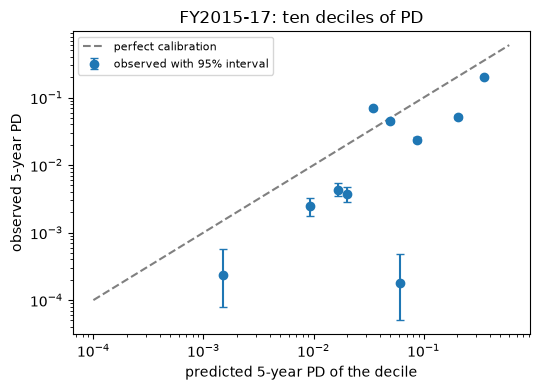

In [11]:
# Count the deciles whose predicted PD falls outside the interval of the observed rate, and draw FY2015-17
for n in names:
    rows = cohorts[n]["outputs"]["calibration"]["rows"]
    above = sum(r["predicted_pd"] > r["ci_high"] for r in rows)
    below = sum(r["predicted_pd"] < r["ci_low"] for r in rows)
    print(f"{n:10s} deciles: {len(rows)} | predicted above the interval: {above} | predicted below it: {below}")

rows = cohorts["fy2015-17"]["outputs"]["calibration"]["rows"]
predicted = np.array([r["predicted_pd"] for r in rows])
observed = np.array([max(r["observed_pd"], 1e-5) for r in rows])
low = np.array([max(r["ci_low"], 1e-5) for r in rows])
high = np.array([r["ci_high"] for r in rows])
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.errorbar(predicted, observed, yerr=[observed - low, high - observed], fmt="o", capsize=3, label="observed with 95% interval")
ax.plot([1e-4, 0.6], [1e-4, 0.6], color="gray", linestyle="--", label="perfect calibration")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("predicted 5-year PD of the decile")
ax.set_ylabel("observed 5-year PD")
ax.set_title("FY2015-17: ten deciles of PD")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()


### Step 7: the ladder against the scorecard

The cohort files also commit the AUC of the six models on each cohort. The next cell puts them side by side. A challenger is worth considering only if it ranks better out of time, not only on the training years, and the cohorts are where that is decided.

In [12]:
# Print the AUC of each model on each cohort (the TabPFN rung is declared absent)
rung_ids = [r["rung_id"] for r in fit["ladder"]]
print(f"{'model':14s}" + "".join(f"{n:>12s}" for n in names))
for rung in rung_ids:
    line = f"{rung:14s}"
    for n in names:
        row = next(r for r in cohorts[n]["outputs"]["rung_comparison"] if r["rung_id"] == rung)
        line += f"{row['auc']:12.4f}"
    print(line)
absent = [r["rung_id"] for r in cohorts[names[0]]["outputs"]["rung_comparison"] if r["auc"] is None]
print("rungs without a number, declared absent:", absent)


model            fy2006-07   fy2008-10   fy2011-14   fy2015-17   fy2018-20
P0-constant         0.5000      0.5000      0.5000      0.5000      0.5000
P1-scorecard        0.8252      0.8149      0.8170      0.7935      0.8264
P2a-l1              0.8264      0.8137      0.8355      0.8055      0.8341
P2b-pltr            0.7696      0.7748      0.8139      0.8489      0.7393
P3-ebm              0.7340      0.7769      0.8277      0.7951      0.7460
P4-lightgbm         0.7967      0.8323      0.8732      0.8367      0.8305
rungs without a number, declared absent: ['P5-tabpfn']


## Results

- **The design is leakage-safe on dates.** All five windows close on the 5-year mark of their last training year, between 2005-09-30 and 2017-09-30, and each closes before the first approval of its test cohort. The vintages carry no censored loan, because each is read at its 5-year mark; the share of loans still active after 60 months (up to 29% in FY2018-20) is counted as non-events, which is correct for a target defined at month 60.
- **Calibration drifts by cohort, and by a lot.** Loans approved in 2006 to 2008 charged off at 21% to 28% within five years, against 7% to 9% predicted: the cohorts that straddle the crisis are strongly under-predicted (gap up to +0.19) even for a model trained to 2002. For FY2011 onwards the gap changes sign and the scorecard over-predicts by 2 to 5 points, because the training windows contain the outcomes of the crisis (FY2015-17 is trained on 1991 to 2009) while the later loans performed much better.
- **The battery reads the two directions differently.** For the crisis cohorts the Jeffreys and binomial tests are red. For FY2011-14, FY2015-17 and FY2018-20 they are green, with p-values near 1, because they ask only whether defaults exceed the PD; Hosmer-Lemeshow and the PSI are red in all five, and the AUC against development is red for FY2015-17 alone (0.823 at development, 0.793 now). The recomputed Jeffreys and Vasicek p-values equal the committed ones.
- **The deciles say where.** In the FY2015-17 cohort the lowest deciles are predicted at several times what was observed, and the interval of the observed rate excludes the predicted PD in all ten deciles (nine above it, one below), which is the picture of a model that learned a riskier world.
- **The ranking is more robust than the level.** The scorecard's AUC by vintage stays between 0.78 and 0.84 across all fifteen vintages, while the level moves by tens of points. The richer models (penalised trees, LightGBM) rank better out of time in FY2015-17 (0.849 and 0.837 against 0.793), though not in every cohort (the penalised trees and the boosting machine rank below the scorecard in FY2018-20), and none repairs the level.

What this notebook does not show: how the models are fitted on the 40,000-loan stratified sample of each window (the pipeline's `data-pipeline/pipeline/cases/c03/fit.py`), nor the recession dynamics inside a vintage. The SBA file is a federal programme, not a bank's SME book; the cohort rows are evidence about this programme, not a statement about the SME book of any bank. The TabPFN rung is declared absent, and no number stands in for it.

## Summary

- A panel is validated out of time: vintages by approval fiscal year, training windows that close on a 5-year mark before the test cohort starts, and a target read only where every loan has had its 60 months.
- The calibration of a scorecard moves by cohort: strongly under-predicted across the crisis, over-predicted after it when the training window contained the crisis.
- The one-sided level tests reject only an under-estimate; reading a model by their lights alone misses the over-estimate, which Hosmer-Lemeshow, the calibration gap and the deciles show.
- The ranking holds better than the level, and challengers are judged on the cohorts, not on the training years.

**What to try next.** Compare the gap of FY2008-10 with a model trained after the crisis, using the cohort windows of `models-sba-7a.json`; then continue with notebook 05, which applies the same discipline to corporate PD at one to five year horizons.

## References

- U.S. Small Business Administration, 7(a) and 504 FOIA loan data (U.S. Government Works). https://data.sba.gov/dataset/7a-504-foia
- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk, sections 2.5.3.1 and 2.5.4.1 and Annex 1 (section 3.1). https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- BCBS (2005), Studies on the validation of internal rating systems, Working Paper 14 (revised): the binomial and the Vasicek-adjusted binomial tests. https://www.bis.org/publications/studies-validation-internal-rating-systems-revised.pdf
- Brown, L. D., Cai, T. T. and DasGupta, A. (2001), Interval estimation for a binomial proportion, Statistical Science 16(2). https://doi.org/10.1214/ss/1009213286
- Hosmer, D. W. and Lemeshow, S. (1980), Goodness of fit tests for the multiple logistic regression model, Communications in Statistics, Theory and Methods 9(10). https://doi.org/10.1080/03610928008827941
- Yurdakul, B. and Naranjo, J. (2020), Statistical properties of the population stability index, Journal of Risk Model Validation 14(4). https://doi.org/10.21314/JRMV.2020.227
- This repository: `docs/design/SDD.md` (the leakage-safe split of C03) and `data-pipeline/pipeline/cases/c03/`.